# ¿Quién se queda atrás en el ICFES? Caldas, Saber 11 de 2022

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cmorregof/taller-cd-ml-2026-2/blob/main/posts/la_brecha_del_icfes_2022.ipynb)

Carlos Manuel Orrego Franco · Taller en Ciencia de Datos y Aprendizaje Automático · Especialización en Estadística · Universidad Nacional de Colombia, Sede Manizales

Este cuaderno reproduce todas las cifras del post de LinkedIn. Corre completo en Colab en un par de minutos: **Entorno de ejecución → Ejecutar todas**.

Responde cuatro preguntas:

1. ¿Cuántos estudiantes de Caldas se quedan atrás en el ICFES, en la ciudad y en el campo?
2. ¿Cuánto pesa la educación de la madre, y qué más acompaña a la ruralidad?
3. ¿Se repite en 2022 lo que se veía en 2020, el año de la pandemia?
4. Si un modelo reparte cupos de refuerzo, ¿a quién encuentra y a quién deja por fuera?

**El dato.** Resultados de Saber 11 que el ICFES publica por estudiante, sin identificación personal, en datos.gov.co: el conjunto [`kgxf-xxbe`](https://www.datos.gov.co/d/kgxf-xxbe), periodo `20224`, que es el calendario A de 2022. Para comparar con 2020 se usa [`rnvb-vnyh`](https://www.datos.gov.co/d/rnvb-vnyh), el mismo del cuaderno de clase.

In [1]:
# Celda de arranque. No hay que cambiarle nada: trae las herramientas del curso.
import pathlib, subprocess, sys
raiz = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path.cwd() / "taller-cd-ml-2026-2"] if (p / "taller" / "datos.py").exists()), None)
if raiz is None:
    subprocess.run(["git", "clone", "-q", "https://github.com/cmorregof/taller-cd-ml-2026-2.git"], check=True)
    raiz = pathlib.Path("taller-cd-ml-2026-2")
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from taller import descargar, procedencia

PALETA = ["#1D4E89", "#D7263D", "#1B998B", "#6C4AB6", "#5BC0EB", "#F49097", "#9AA5B1"]      # colores del curso
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=PALETA), "axes.titleweight": "bold", "figure.dpi": 110})
print("Herramientas listas.")

Herramientas listas.


In [2]:
import requests
from taller.icfes import EDUCACION, PERSONAS, CUARTOS, preparar, tasa_por, tramos, competir, asignar_cupos, auditar

API = "https://www.datos.gov.co/resource/kgxf-xxbe"
PERIODO = "20224"

def consultar(parametros, formato="json"):
    respuesta = requests.get(f"{API}.{formato}", params=parametros, timeout=300)
    respuesta.raise_for_status()
    return respuesta

## 1. Los datos y su trampa

Bajamos solo los estudiantes de colegios de Caldas en el periodo de 2022.

In [3]:
import io
crudo = pd.read_csv(io.StringIO(consultar({"$where": f"cole_depto_ubicacion='CALDAS' and periodo='{PERIODO}'",
                                            "$limit": 50000}, "csv").text), dtype=str)
print("Filas:", len(crudo), "| Estudiantes distintos:", crudo["estu_consecutivo"].nunique())

Filas: 19864 | Estudiantes distintos: 9932


Hay el doble de filas que de estudiantes. Cada estudiante aparece dos veces, con los mismos datos. Si no lo notamos, cada porcentaje se calcularía sobre una tabla duplicada. En este caso las proporciones no cambiarían, pero los conteos y los errores estándar sí. Quitamos los repetidos y también los puntajes en cero.

In [4]:
idénticas = crudo.duplicated().sum()
print("Filas idénticas a otra:", idénticas)
datos = crudo.drop_duplicates("estu_consecutivo").reset_index(drop=True)
puntaje = pd.to_numeric(datos["punt_global"], errors="coerce")
datos = datos[puntaje > 0].reset_index(drop=True)
puntaje = pd.to_numeric(datos["punt_global"])
print("Estudiantes de Caldas con puntaje:", len(datos))

Filas idénticas a otra: 9932
Estudiantes de Caldas con puntaje: 9932


## 2. ¿Qué es quedarse atrás?

Decimos que un estudiante **se queda atrás** si su puntaje global está entre el 25 % más bajo de **todo el país**. La tabla de 2022 no trae el percentil nacional, así que lo calculamos. En vez de bajar más de un millón de filas, le preguntamos a la API cuántos estudiantes del país tienen un puntaje menor o igual a cada valor, y buscamos el umbral por bisección. Los repetidos no cambian la proporción, porque todos aparecen dos veces.

In [5]:
def contar(condición):
    return int(consultar({"$select": "count(*)", "$where": f"periodo='{PERIODO}' and punt_global::number > 0 and {condición}"}).json()[0]["count"])

total = contar("true")
bajo, alto = 150, 300                       # el mayor puntaje t con a lo sumo 25 % del país en t o menos
while bajo < alto:
    medio = (bajo + alto + 1) // 2
    if contar(f"punt_global::number <= {medio}") / total <= 0.25:
        bajo = medio
    else:
        alto = medio - 1
UMBRAL = bajo
print(f"Umbral: {UMBRAL} puntos")
print(f"País con {UMBRAL} o menos: {100 * contar(f'punt_global::number <= {UMBRAL}') / total:.2f} %")
print(f"País con {UMBRAL + 1} o menos: {100 * contar(f'punt_global::number <= {UMBRAL + 1}') / total:.2f} %")

y = (puntaje <= UMBRAL).astype(int).rename("atrás")
print(f"En Caldas se queda atrás el {100 * y.mean():.1f} %")

Umbral: 209 puntos


País con 209 o menos: 24.97 %


País con 210 o menos: 25.70 %
En Caldas se queda atrás el 21.6 %


## 3. La ciudad, el campo y la madre

In [6]:
zona = datos["cole_area_ubicacion"].str.lower()
madre = datos["fami_educacionmadre"]
grupo_madre = np.select(
    [madre.isin(["Ninguno", "Primaria incompleta", "Primaria completa"]),
     madre.isin(["Educación profesional incompleta", "Educación profesional completa", "Postgrado"])],
    ["primaria o menos", "profesional"], default="intermedia o sin dato")

print((100 * y.groupby(zona).mean()).round(1).rename("% que se queda atrás").to_string(), "\n")
tabla = pd.DataFrame({"atrás": y, "zona": zona, "madre": grupo_madre})
resumen = tabla.groupby(["zona", "madre"])["atrás"].agg(["size", "mean"])
resumen["mean"] = (100 * resumen["mean"]).round(1)
resumen.columns = ["estudiantes", "% que se queda atrás"]
resumen

cole_area_ubicacion
rural     32.7
urbano    18.7 



estudiantes  % que se queda atrás
zona   madre                                                   
rural  intermedia o sin dato          958                  30.9
       primaria o menos              1014                  36.0
       profesional                     97                  16.5
urbano intermedia o sin dato         4951                  17.3
       primaria o menos              1659                  31.0
       profesional                   1253                   7.7

"Profesional" incluye a la madre que llegó a la universidad, terminara o no, y a la que hizo posgrado. Fíjense en el tamaño de cada grupo antes de creer una cifra: en el campo hay pocas madres profesionales.

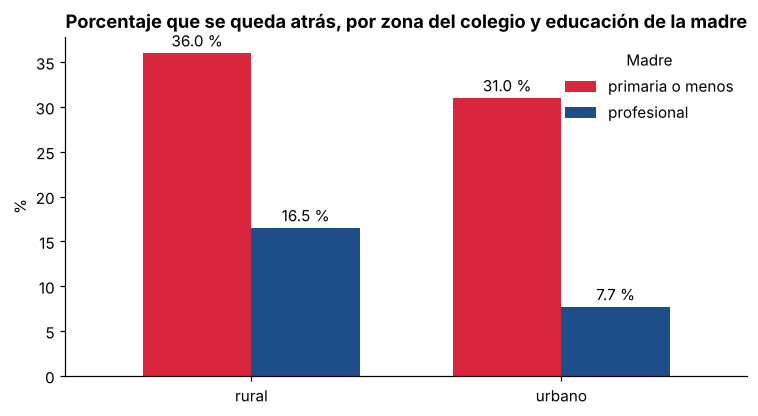

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
vista = resumen["% que se queda atrás"].unstack("madre")[["primaria o menos", "profesional"]]
vista.plot.bar(ax=ax, color=["#D7263D", "#1D4E89"], rot=0, width=0.7)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f %%", padding=2)
ax.set(title="Porcentaje que se queda atrás, por zona del colegio y educación de la madre", xlabel="", ylabel="%")
ax.legend(title="Madre", frameon=False); plt.show()

Lo rural no es una sola desventaja. Varias llegan juntas al mismo estudiante.

In [8]:
acumulado = pd.DataFrame({
    "% con internet en casa": 100 * (datos["fami_tieneinternet"] == "Si").groupby(zona).mean(),
    "% con madre de primaria o menos": 100 * pd.Series(grupo_madre == "primaria o menos").groupby(zona).mean(),
}).round(1)
acumulado          # quienes no respondieron cuentan en el total

,% con internet en casa,% con madre de primaria o menos
cole_area_ubicacion,,
rural,40.8,49.0
urbano,79.0,21.1


In [9]:
municipios = tasa_por(y, datos["cole_mcpio_ubicacion"].str.title())
municipios = municipios[municipios["n"] >= 80].round(1)
print("Municipios con 80 o más estudiantes, de menor a mayor porcentaje que se queda atrás:")
municipios

Municipios con 80 o más estudiantes, de menor a mayor porcentaje que se queda atrás:


,n,tasa,ee
cole_mcpio_ubicacion,,,
Villamaría,618,14.6,1.4
Manizales,4035,15.4,0.6
Aguadas,247,16.6,2.4
Samaná,231,20.3,2.6
Chinchiná,485,20.8,1.8
Viterbo,137,23.4,3.6
Neira,209,23.4,2.9
Marquetalia,167,24.0,3.3
Anserma,311,24.1,2.4


## 4. ¿Se repite lo de 2020?

En 2020 hice el mismo análisis con el conjunto del cuaderno de clase. Allí la definición usa el percentil nacional que publica el ICFES. Ese año, en el campo, los hijos de madres profesionales se quedaban atrás casi tanto como el resto. Veamos si eso se sostiene.

In [10]:
X20, y20, colegio20, datos20 = preparar(descargar("saber11", departamento="CALDAS"))
madre20 = datos20["fami_educacionmadre"]
grupo20 = np.select(
    [madre20.isin(["Ninguno", "Primaria incompleta", "Primaria completa"]),
     madre20.isin(["Educación profesional incompleta", "Educación profesional completa", "Postgrado"])],
    ["primaria o menos", "profesional"], default="intermedia o sin dato")
t20 = pd.DataFrame({"atrás": y20.values, "zona": datos20["cole_area_ubicacion"].str.lower().values, "madre": grupo20})

comparación = pd.concat({
    "2020": t20.groupby(["zona", "madre"])["atrás"].agg(["size", "mean"]),
    "2022": tabla.groupby(["zona", "madre"])["atrás"].agg(["size", "mean"]),
}, axis=1)
for año in ["2020", "2022"]:
    comparación[(año, "mean")] = (100 * comparación[(año, "mean")]).round(1)
comparación = comparación.rename(columns={"size": "estudiantes", "mean": "% atrás"})
comparación.loc[[("rural", "primaria o menos"), ("rural", "profesional"), ("urbano", "primaria o menos"), ("urbano", "profesional")]]

[saber11] Descargo de la fuente oficial: ICFES, en datos.gov.co, conjunto rnvb-vnyh.


[saber11] Listo: 9.942 filas.


2020                2022        
                        estudiantes % atrás estudiantes % atrás
zona   madre                                                   
rural  primaria o menos        1144    39.6        1014    36.0
       profesional               72    33.3          97    16.5
urbano primaria o menos        1953    33.3        1659    31.0
       profesional             1213     8.4        1253     7.7

En el campo, el grupo de madres profesionales pasó de 33,3 % a 16,5 %. Son 72 estudiantes en 2020 y 97 en 2022, y la definición del umbral no es idéntica en los dos años. Con grupos así de pequeños, una diferencia grande puede ser azar. Por eso el post no se construye sobre ese dato.

## 5. Un modelo que reparte cupos

Supongamos que hay cupos de refuerzo para uno de cada cuatro estudiantes y que hay que repartirlos al momento de la inscripción, antes del examen. El modelo solo puede usar lo que se sabe en ese momento: el hogar, la familia y el colegio. Nunca ve los puntajes.

Separamos colegios enteros en entrenamiento (60 %), validación (20 %) y prueba (20 %), para que el modelo se evalúe en colegios que no conoce. Compiten dos reglas sin modelo (un sorteo y "primero los de madre con menos educación") y tres modelos. El ganador se escoge en validación y se reporta en prueba. La métrica es la **captación**: de quienes se iban a quedar atrás, qué porcentaje recibe cupo.

In [11]:
edad = 2022 - pd.to_numeric(datos["estu_fechanacimiento"].str[-4:], errors="coerce")
sí = lambda col: (datos[col] == "Si").astype(float).where(datos[col].notna())
X = pd.DataFrame(index=datos.index)
X["mujer"] = (datos["estu_genero"] == "F").astype(float).where(datos["estu_genero"].notna())
X["edad"] = edad.where(edad.between(13, 70))
X["estrato"] = pd.to_numeric(datos["fami_estratovivienda"].str.extract(r"(\d)")[0], errors="coerce")
X["sin_estrato"] = (datos["fami_estratovivienda"] == "Sin Estrato").astype(float)
X["educacion_madre"] = datos["fami_educacionmadre"].map(EDUCACION)
X["educacion_padre"] = datos["fami_educacionpadre"].map(EDUCACION)
for cosa in ["internet", "computador", "automovil", "lavadora"]:
    X[cosa] = sí(f"fami_tiene{cosa}")
X["personas_hogar"] = datos["fami_personashogar"].map(PERSONAS)
X["cuartos"] = datos["fami_cuartoshogar"].map(CUARTOS)
X["colegio_oficial"] = (datos["cole_naturaleza"] == "OFICIAL").astype(float)
X["colegio_rural"] = (datos["cole_area_ubicacion"] == "RURAL").astype(float)
X["nocturna_o_sabatina"] = datos["cole_jornada"].isin(["NOCHE", "SABATINA"]).astype(float)
X["jornada_completa"] = datos["cole_jornada"].isin(["COMPLETA", "UNICA"]).astype(float)
colegio = datos["cole_cod_dane_establecimiento"]

E, V, P = tramos(X, y, colegio)
resultados, puntajes = competir(X, y, E, V, P, cupo=0.25)
mejor = resultados.drop(index="sorteo")["captación en validación"].idxmax()
print("Ganador en validación:", mejor)
(100 * resultados[["captación en validación", "captación en prueba"]]).round(1)

Ganador en validación: bosque


,captación en validación,captación en prueba
sorteo,21.1,23.3
regla: educación de la madre,41.0,36.0
logística,45.4,49.9
árbol,46.2,48.9
bosque,46.8,51.6


## 6. La auditoría

Una buena captación total puede esconder un mal reparto. Miramos, en los colegios de prueba, a quién le llegaron los cupos según la jornada.

In [12]:
cupos = asignar_cupos(puntajes[mejor], cupo=0.25)
jornada = X["nocturna_o_sabatina"].map({1.0: "nocturna o sabatina", 0.0: "diurna"})
auditoría = auditar(y, cupos, jornada)
auditoría["captación"] = 100 * auditoría["captación"]
display(auditoría.round(1))

nocturna = X["nocturna_o_sabatina"] == 1
print(f"En todo Caldas, jornada nocturna o sabatina: {int(nocturna.sum())} estudiantes, "
      f"se queda atrás el {100 * y[nocturna].mean():.1f} %, mediana de edad {X.loc[nocturna, 'edad'].median():.0f} años.")
print(f"Jornada diurna: mediana de edad {X.loc[~nocturna, 'edad'].median():.0f} años.")

,n,% que quedó abajo,% con cupo,captación
diurna,1646.0,18.9,16.6,35.0
nocturna o sabatina,184.0,57.6,100.0,100.0


En todo Caldas, jornada nocturna o sabatina: 882 estudiantes, se queda atrás el 52.2 %, mediana de edad 20 años.
Jornada diurna: mediana de edad 17 años.


El modelo le da cupo a todos los estudiantes de jornada nocturna o sabatina de los colegios de prueba. Son estudiantes mayores, y en esas jornadas más de la mitad se queda atrás, así que la jornada es una señal fácil de aprender. En la jornada diurna, en cambio, solo alcanza a una parte de quienes lo necesitaban, y ahí está la mayoría de los estudiantes.

## Límites

- Es una foto de un año y de un departamento. Los grupos pequeños, como el de madres profesionales en el campo, se mueven mucho de un año a otro.
- El umbral de 2022 se calculó con los datos de todo el país en datos.gov.co. El de 2020 es el percentil que publica el ICFES. Son muy parecidos, pero no idénticos.
- El conjunto de 2022 no trae algunas variables que sí tiene el de 2020, como los libros en casa, las horas de trabajo y el índice socioeconómico. El modelo de 2022 usa menos información.
- Asociación no es causa. Que la educación de la madre separe a los estudiantes no dice qué pasaría si cambiara.